# Corrigé du TP4, version mini : premiers graphiques

## Objectifs

En une demi-heure, essayer le raccourci de pandas puis les trois bibliothèques de visualisation sur les indicateurs du TP3 :

- pandas : un aperçu en une ligne avec `.plot()` ;
- matplotlib : une courbe et des barres soignées ;
- seaborn : une boîte à moustaches et une heatmap, en une ligne chacune ;
- plotly : un graphique interactif, exporté en HTML.

## Les données

- `indicateurs_mois_region.parquet` : une ligne par mois et par région
- `ventes_consolidees.parquet` : une ligne par commande

## Comment travailler

- Complète les cellules marquées `# TODO`, en utilisant les noms de variables indiqués.
- Pour chaque graphique, le **résultat attendu** est une image : ton graphique doit lui ressembler, sans être identique au pixel près.
- Les cellules `# Vérification` contrôlent ton travail avec `assert` : exécute-les sans les modifier. Elles inspectent la figure `fig` et le graphique `ax` : garde ces noms. Si tout est juste, elles affichent `OK`.
- La question **Pour aller plus loin** est facultative.

## Partie 0 : environnement et données

Dans l'environnement virtuel des TP précédents, installe les trois bibliothèques :

```bash
python -m pip install matplotlib seaborn plotly
```

Lance `jupyter lab` depuis le dossier de ce TP, puis exécute la cellule suivante : elle charge les deux tables et prépare les deux agrégats utilisés dans le TP.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import seaborn as sns

indicateurs = pd.read_parquet("ressources/indicateurs_mois_region.parquet")
ventes = pd.read_parquet("ressources/ventes_consolidees.parquet")

# chiffre d'affaires de chaque mois, et de chaque région (trié par ordre croissant)
mensuel = indicateurs.groupby("mois")["ca"].sum()
par_region = indicateurs.groupby("region")["ca"].sum().sort_values()
par_region


region
Bretagne                 41079.71
Occitanie                50318.18
Hauts-de-France          53467.33
Auvergne-Rhône-Alpes     64856.25
Nouvelle-Aquitaine       71843.18
Île-de-France           127936.94
Name: ca, dtype: float64

### Question 0.1

Avant de soigner un graphique, on jette souvent un coup d'œil rapide avec la méthode `.plot()` de pandas, qui appelle matplotlib et renvoie le graphique. Trace `mensuel` en une seule ligne, avec des marqueurs ronds : `ax = mensuel.plot(marker="o")`. Que pandas a-t-il réglé tout seul ? Que manque-t-il ?

**Résultat attendu** :

![Résultat attendu de la question 0.1](attendus/q0_1.png)

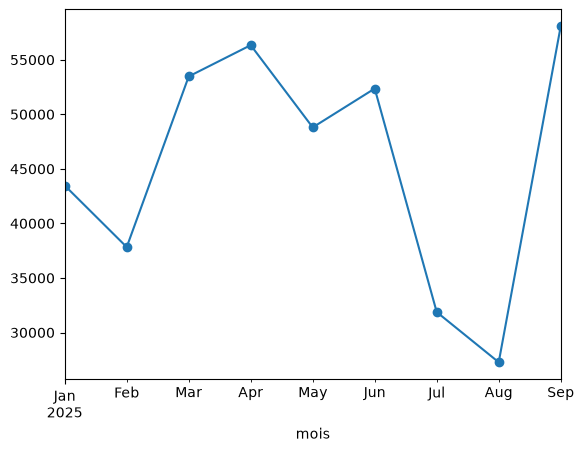

In [2]:
ax = mensuel.plot(marker="o")


In [3]:
# Vérification
assert len(ax.lines) == 1 and len(ax.lines[0].get_xdata()) == 9, "il faut une seule courbe, avec un point par mois"
print("Question 0.1 : OK")


Question 0.1 : OK


**Réponse** : pandas a placé les mois en abscisse, avec des dates lisibles, et a nommé l'axe horizontal d'après l'index (`mois`). Il manque un titre, le nom et l'unité de l'axe vertical, et l'axe ne part pas de zéro. C'est l'objet de la question 1.1. Les autres types s'écrivent de la même façon : `.plot.barh()`, `.plot.hist()`, `.plot.scatter(x=..., y=...)`.

## Partie 1 : matplotlib

On crée toujours la figure et son graphique avec `fig, ax = plt.subplots(figsize=(8, 4))`, puis on agit sur `ax`.

### Question 1.1

Trace l'évolution du chiffre d'affaires mensuel (`mensuel`) avec une courbe et des marqueurs ronds (`marker="o"`). Ajoute un titre, un nom à l'axe vertical avec son unité, et fais partir l'axe vertical de zéro.

**Résultat attendu** :

![Résultat attendu de la question 1.1](attendus/q1_1.png)

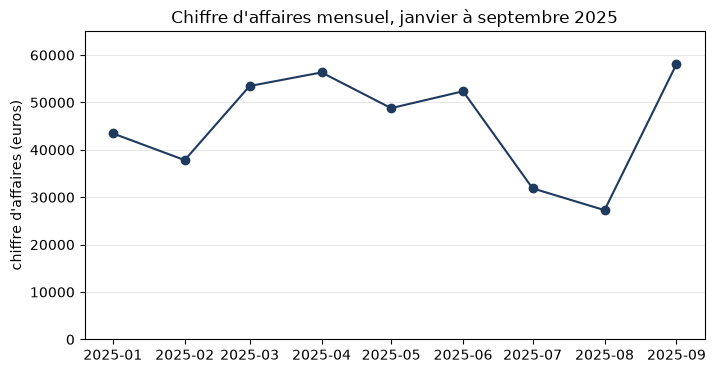

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mensuel.index, mensuel.values, marker="o", color="#1F3A5F")
ax.set_title("Chiffre d'affaires mensuel, janvier à septembre 2025")
ax.set_ylabel("chiffre d'affaires (euros)")
ax.set_ylim(0, 65000)
ax.grid(axis="y", alpha=0.3)


In [5]:
# Vérification
assert len(ax.lines) == 1 and len(ax.lines[0].get_xdata()) == 9, "il faut une seule courbe, avec un point par mois"
assert ax.get_title() != "", "le graphique doit avoir un titre"
assert ax.get_ylabel() != "", "l'axe vertical doit être nommé, avec son unité"
assert ax.get_ylim()[0] == 0, "l'axe vertical doit partir de zéro : ax.set_ylim(0, ...)"
print("Question 1.1 : OK")


Question 1.1 : OK


### Question 1.2

Trace le chiffre d'affaires par région (`par_region`) en barres horizontales (`ax.barh`), la plus grande en haut. Donne au graphique un titre qui énonce son message, nomme l'axe horizontal, et écris le montant au bout de chaque barre avec `ax.bar_label(barres, fmt="%.0f")`, où `barres` est le résultat de `ax.barh`.

**Résultat attendu** :

![Résultat attendu de la question 1.2](attendus/q1_2.png)

(0.0, 150000.0)

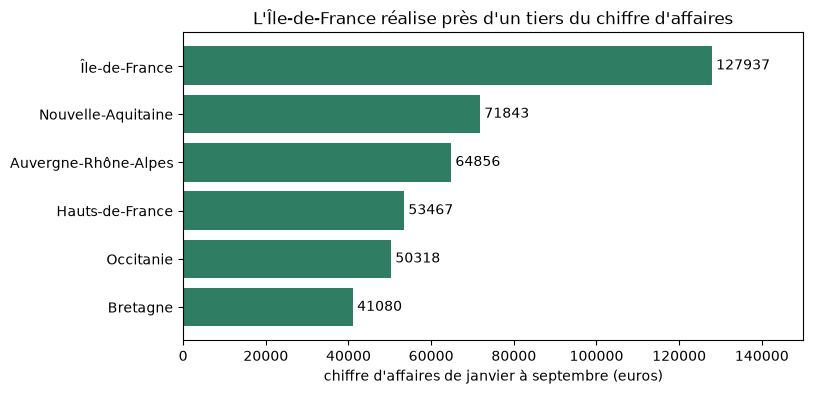

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
barres = ax.barh(par_region.index, par_region.values, color="#2F7D62")
ax.bar_label(barres, fmt="%.0f", padding=3)
ax.set_title("L'Île-de-France réalise près d'un tiers du chiffre d'affaires")
ax.set_xlabel("chiffre d'affaires de janvier à septembre (euros)")
ax.set_xlim(0, 150000)


In [7]:
# Vérification
largeurs = [barre.get_width() for barre in ax.patches]
assert len(largeurs) == 6, "il faut une barre par région"
assert largeurs == sorted(largeurs), "la plus grande barre doit être en haut : trace par_region, trié par ordre croissant"
assert len(ax.texts) == 6, "écris le montant de chaque barre avec ax.bar_label"
assert ax.get_title() != "" and ax.get_xlabel() != "", "il faut un titre et un axe horizontal nommé"
print("Question 1.2 : OK")


Question 1.2 : OK


## Partie 2 : seaborn

seaborn part d'un DataFrame et de noms de colonnes. Chaque fonction dessine dans un graphique matplotlib : passe toujours `ax=ax`. La cellule suivante applique un style sobre à tous les graphiques qui suivent.

In [8]:
sns.set_theme(style="whitegrid")


### Question 2.1

Compare le montant des commandes (`ventes`, colonne `montant`) entre catégories avec `sns.boxplot`, dans `fig, ax = plt.subplots(figsize=(8, 4))`. Ajoute un titre et nomme l'axe vertical. Quelle catégorie a les commandes les plus élevées ?

**Résultat attendu** :

![Résultat attendu de la question 2.1](attendus/q2_1.png)

Text(0, 0.5, 'montant de la commande (euros)')

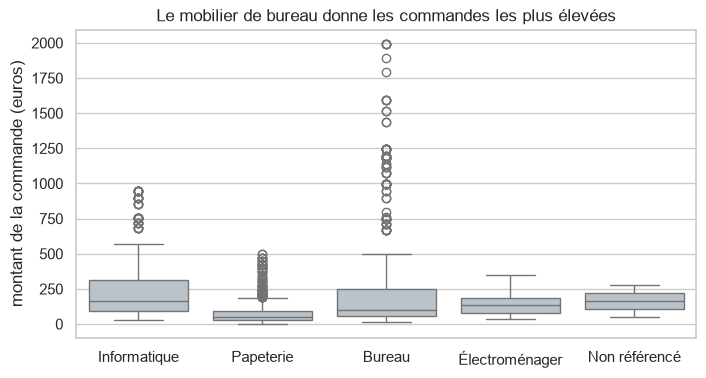

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=ventes, x="categorie", y="montant", color="#B8C2CC", ax=ax)
ax.set_title("Le mobilier de bureau donne les commandes les plus élevées")
ax.set_xlabel("")
ax.set_ylabel("montant de la commande (euros)")


In [10]:
# Vérification
categories = {etiquette.get_text() for etiquette in ax.get_xticklabels()}
assert categories == set(ventes["categorie"]), "il faut une boîte par catégorie : x=\"categorie\""
assert ax.get_title() != "" and ax.get_ylabel() != "", "il faut un titre et un axe vertical nommé"
print("Question 2.1 : OK")


Question 2.1 : OK


**Réponse** : Le bureau : ses valeurs extrêmes montent jusqu'à près de 2 000 euros (lots de chaises ergonomiques et bureaux assis-debout). La boîte résume la distribution : la médiane au milieu, la moitié des commandes dans la boîte, les points isolés au-delà des moustaches.

### Question 2.2

Construis dans `taux` le tableau du taux de réalisation de l'objectif, avec les régions en lignes et les mois en colonnes :

```python
taux = indicateurs.pivot_table(index="region",
                               columns=indicateurs["mois"].dt.strftime("%m/%y"),
                               values="taux_realisation")
```

Trace-le avec `sns.heatmap` dans `fig, ax = plt.subplots(figsize=(9, 4))`, en écrivant les valeurs en pourcentage (`annot=True, fmt=".0%"`), avec la palette `"RdBu"` centrée sur 100 % (`center=1`) et sans barre de couleur (`cbar=False`). Que se passe-t-il en juillet et en août ?

**Résultat attendu** :

![Résultat attendu de la question 2.2](attendus/q2_2.png)

Text(76.53480360243056, 0.5, '')

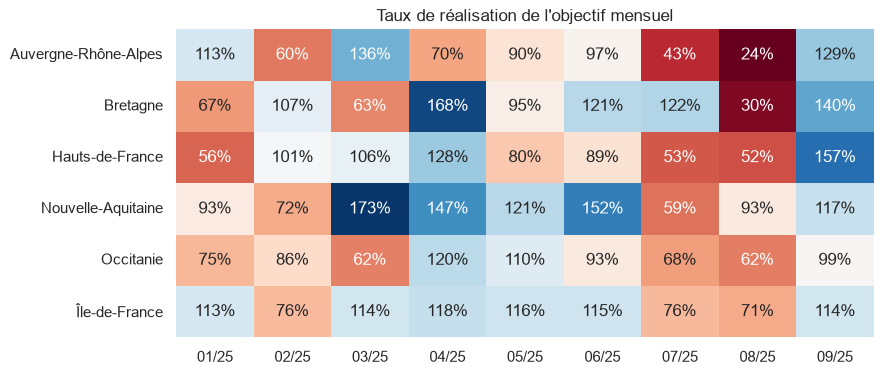

In [11]:
taux = indicateurs.pivot_table(
    index="region",
    columns=indicateurs["mois"].dt.strftime("%m/%y"),
    values="taux_realisation",
)

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(taux, annot=True, fmt=".0%", cmap="RdBu", center=1, cbar=False, ax=ax)
ax.set_title("Taux de réalisation de l'objectif mensuel")
ax.set_xlabel("")
ax.set_ylabel("")


In [12]:
# Vérification
assert taux.shape == (6, 9), "taux doit avoir les 6 régions en lignes et les 9 mois en colonnes"
assert len(ax.texts) == 54, "écris la valeur de chaque case avec annot=True"
print("Question 2.2 : OK")


Question 2.2 : OK


**Réponse** : En juillet et en août, presque toutes les cases sont rouges : seule la Bretagne atteint son objectif en juillet, aucune région en août. La heatmap fait ressortir d'un coup d'œil cet effet saisonnier, qui demanderait de lire 54 nombres dans un tableau.

## Partie 3 : plotly

Les graphiques plotly sont interactifs : survole-les, zoome, clique sur la légende pour masquer une série.

### Question 3.1

Crée avec `px.line` un graphique du chiffre d'affaires mensuel par région (`color="region"`), avec des marqueurs (`markers=True`) et un titre, dans une variable `fig_ca`. Ajoute le nombre de commandes dans l'info-bulle avec `hover_data=["nb_commandes"]`. Termine par `fig_ca.show()`, puis survole les courbes et clique sur une région dans la légende.

In [13]:
fig_ca = px.line(
    indicateurs,
    x="mois",
    y="ca",
    color="region",
    markers=True,
    hover_data=["nb_commandes"],
    title="Chiffre d'affaires mensuel par région",
    template="simple_white",
)
fig_ca.show()


In [14]:
# Vérification
assert len(fig_ca.data) == 6, "il faut une courbe par région : color=\"region\""
assert fig_ca.layout.title.text, "ajoute un titre avec title=..."
assert "nb_commandes" in fig_ca.data[0].hovertemplate, "ajoute le nombre de commandes à l'info-bulle avec hover_data"
print("Question 3.1 : OK")


Question 3.1 : OK


### Question 3.2

Exporte `fig_ca` dans le fichier `ca_mensuel_regions.html` avec `write_html`, puis ouvre ce fichier dans ton navigateur : le graphique reste-t-il interactif ?

In [15]:
fig_ca.write_html("ca_mensuel_regions.html")


In [16]:
# Vérification
assert Path("ca_mensuel_regions.html").exists(), "exporte fig_ca en ca_mensuel_regions.html"
print("Question 3.2 : OK")


Question 3.2 : OK


**Réponse** : Oui : le fichier HTML s'ouvre dans n'importe quel navigateur, sans Python, et garde le survol, le zoom et la légende cliquable. C'est l'intérêt de plotly pour partager une exploration.

## Partie 4 : un graphique trompeur

### Pour aller plus loin 4.1

Exécute la cellule suivante telle quelle : elle compare le panier moyen des régions. En quoi ce graphique trompe-t-il ? Corrige-le, en gardant les noms `fig` et `ax`, et donne-lui un titre qui énonce le message.

**Résultat attendu** :

![Résultat attendu de la question 4.1](attendus/q4_1.png)

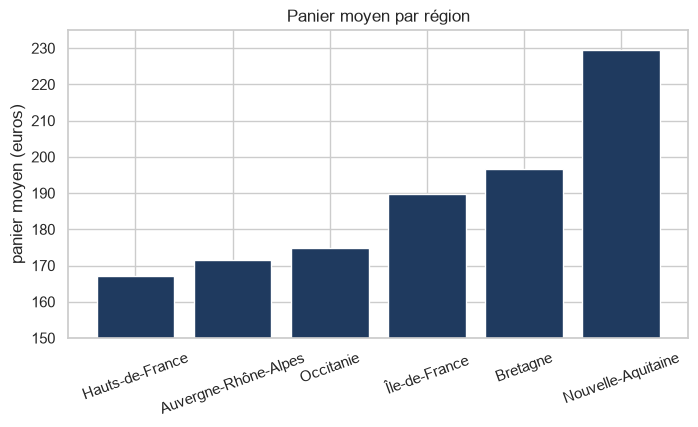

In [17]:
panier_region = ventes.groupby("region")["montant"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(panier_region.index, panier_region.values, color="#1F3A5F")
ax.set_ylim(150, 235)
ax.set_title("Panier moyen par région")
ax.set_ylabel("panier moyen (euros)")
ax.tick_params(axis="x", labelrotation=20)


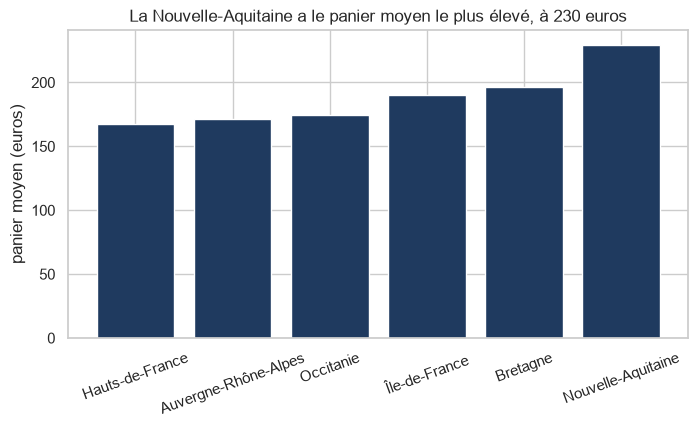

In [18]:
panier_region = ventes.groupby("region")["montant"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(panier_region.index, panier_region.values, color="#1F3A5F")
ax.set_title("La Nouvelle-Aquitaine a le panier moyen le plus élevé, à 230 euros")
ax.set_ylabel("panier moyen (euros)")
ax.tick_params(axis="x", labelrotation=20)


In [19]:
# Vérification
assert len(ax.patches) == 6, "il faut une barre par région"
assert ax.get_ylim()[0] == 0, "l'axe d'un graphique en barres doit partir de zéro"
print("Question 4.1 : OK")


Question 4.1 : OK


**Réponse** : L'axe vertical commence à 150 euros : la longueur des barres ne représente plus les valeurs. La barre de la Nouvelle-Aquitaine paraît près de cinq fois plus haute que celle des Hauts-de-France, alors que son panier moyen n'est que 37 % plus élevé (230 euros contre 167 euros). Un graphique en barres part toujours de zéro.